# Visual examples: image preprocessing and detector output

This short notebook runs on **CPU** using the bundled COCO example. It needs Pillow, matplotlib and IPython; no GPU, checkpoint, dataset download or training is needed. Open it from the repository root and run the three code cells in order.

1. Load the image and its original human captions.
2. Show the real ResNet resize-and-pad preprocessing.
3. Display previously recorded detector boxes and generated captions.

**Recorded results are not recomputed here.** The detector/caption figures and captions come from the frozen epoch-11 model. The resize figure is recreated by this notebook.

Source: COCO val2017 image **113403**, [original Flickr source](https://www.flickr.com/photo.gne?id=3713015524), [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/). The bundled JPEG is unchanged; figures add resizing, padding or recorded boxes. All five references below are copied from the original COCO annotation file. See [visual notes](docs/VISUAL_EXAMPLES.md) for the full explanation.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image,ImageOps
from IPython.display import display,Markdown

PROJECT_DIR=Path.cwd()
ASSET_DIR=PROJECT_DIR/"docs/assets/data_examples"
RESULTS_DIR=PROJECT_DIR/"results/followup_20261126/resolution"
IMAGE_PATH=ASSET_DIR/"coco_val2017_000000113403.jpg"

# Load one bundled image and the saved experimental evidence
with Image.open(IMAGE_PATH) as source:
    image=ImageOps.exif_transpose(source).convert("RGB")

metadata=json.loads((ASSET_DIR/"coco_val2017_000000113403.json").read_text(encoding="utf-8"))
comparison=json.loads((RESULTS_DIR/"teddy_bears/comparison.json").read_text(encoding="utf-8"))
print("COCO image:",metadata["image"]["id"])
print("Original size:",image.size,"(width,height)")
print("This notebook uses CPU image processing and recorded model outputs.")


COCO image: 113403
Original size: (640, 451) (width,height)
This notebook uses CPU image processing and recorded model outputs.


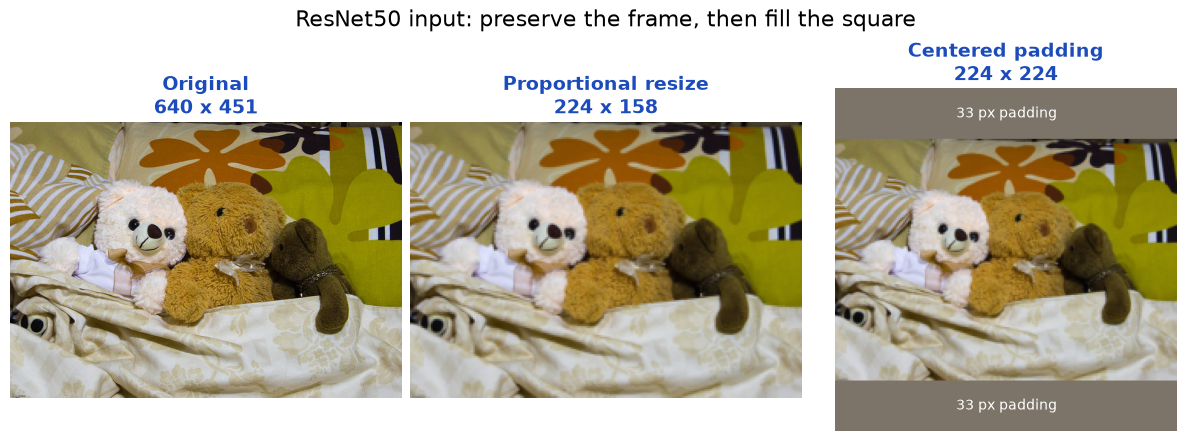

Resize: 640x451 -> 224x158
Padding: top=33, bottom=33; final size=(224, 224)
No crop. Aspect ratio is preserved up to integer pixel rounding.
The detector uses the original photo with its own resize, not this 224x224 image.


In [2]:
# Keep the whole image and its proportions, then add centered padding
resized=ImageOps.contain(image,(224,224),method=Image.Resampling.BILINEAR)
padded=ImageOps.pad(image,(224,224),method=Image.Resampling.BILINEAR,color=(124,116,104))
top=(224-resized.height)//2
bottom=224-resized.height-top

fig,axes=plt.subplots(1,3,figsize=(12,4.3),layout="constrained")
images=[image,resized,padded]
titles=["Original\n640 x 451","Proportional resize\n224 x 158","Centered padding\n224 x 224"]

for axis,example,title in zip(axes,images,titles):
    axis.imshow(example)
    axis.set_title(title,color="#1C4BBC",fontsize=14,fontweight="bold")
    axis.axis("off")

axes[2].text(112,16,"33 px padding",ha="center",va="center",color="white",fontsize=10)
axes[2].text(112,207,"33 px padding",ha="center",va="center",color="white",fontsize=10)
fig.suptitle("ResNet50 input: preserve the frame, then fill the square",fontsize=16)
fig.savefig(ASSET_DIR/"resize_padding.png",dpi=150,bbox_inches="tight")
plt.show()

print(f"Resize: {image.width}x{image.height} -> {resized.width}x{resized.height}")
print(f"Padding: top={top}, bottom={bottom}; final size={padded.size}")
print("No crop. Aspect ratio is preserved up to integer pixel rounding.")
print("The detector uses the original photo with its own resize, not this 224x224 image.")


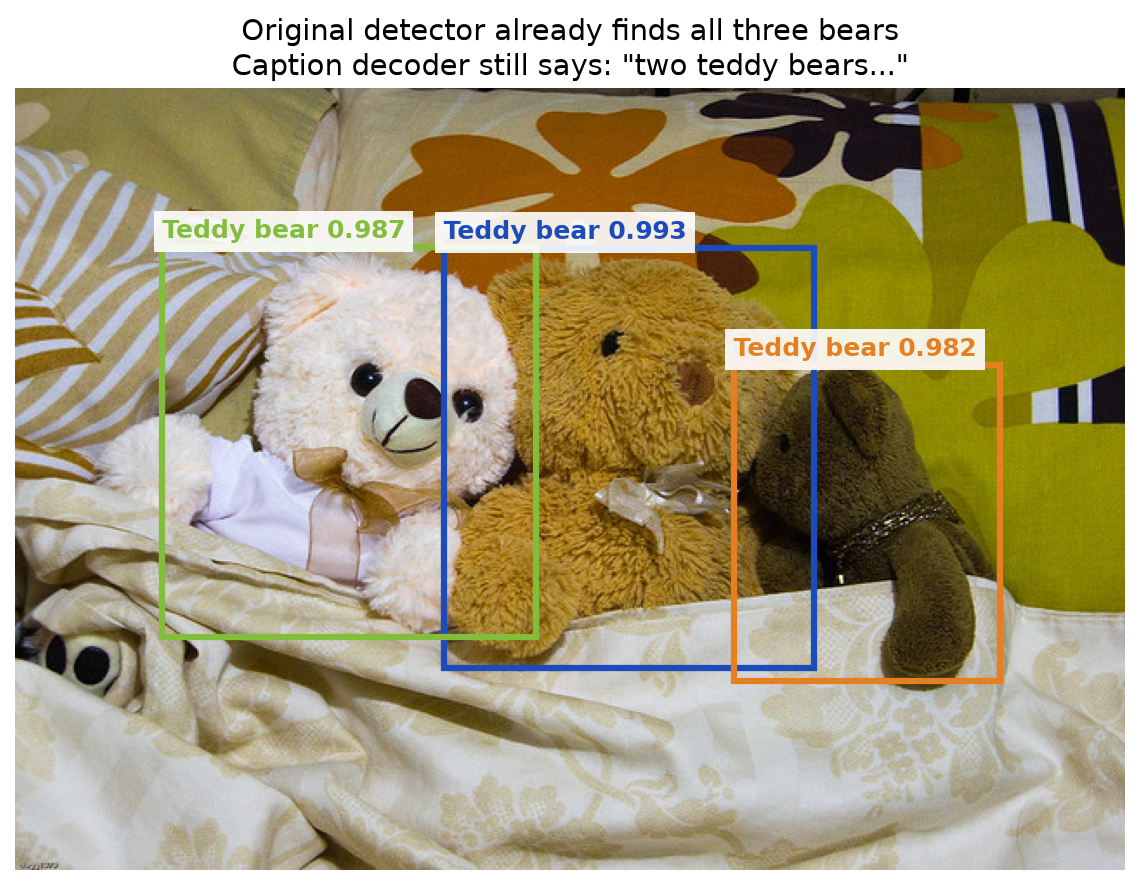

The figure shows three strong, distinct teddy-bear boxes that survived region selection. The full selection also contains a weaker overlapping teddy-bear box and other regions. The caption still says **two**, so this example is not simply a missing detection.

| Input setting | Recorded caption | Recorded generation time |
|---|---|---:|
| baseline | two teddy bears are laying on a bed . | 1.136 s |
| detector_1200 | a teddy bear laying on top of a bed . | 0.949 s |
| resnet_448 | two stuffed animals are laying on a bed . | 1.024 s |
| both_larger | a teddy bear laying on top of a bed . | 0.959 s |


Recorded checkpoint: original frozen-CNN Fusion, epoch 11
Recorded device: NVIDIA GeForce RTX 4060 Laptop GPU
Times include image features and beam search; model loading is excluded.


### Original human captions

- Three teddy bears laying in bed under the covers.
- A group of stuffed animals sitting next to each other in bed.
- A white, beige and brown baby bear under a beige/white comforter.
- A trio of teddy bears bundled up on a bed.
- Three stuffed animals lay in a bed cuddled together.

**Conclusion:** none of the four input settings fixed the count in this example. The full 5000-image comparison also favored the original preprocessing. A single example illustrates an error; it does not measure an error rate.

In [3]:
# These boxes were recorded earlier; no detector or caption model is run here
with Image.open(RESULTS_DIR/"three_bears_diagnosis.png") as figure:
    display(figure.copy())

display(Markdown("The figure shows three strong, distinct teddy-bear boxes that survived region selection. "
                 "The full selection also contains a weaker overlapping teddy-bear box and other regions. "
                 "The caption still says **two**, so this example is not simply a missing detection."))

# Compare real saved captions for the same image and unchanged model weights
table="| Input setting | Recorded caption | Recorded generation time |\n|---|---|---:|\n"
for row in comparison["records"]:
    table+=f"| {row['mode']} | {row['caption']} | {row['total_seconds']:.3f} s |\n"
display(Markdown(table))
print("Recorded checkpoint:",comparison["checkpoint"])
print("Recorded device:",comparison["gpu"])
print("Times include image features and beam search; model loading is excluded.")

# Keep the original human references, without vocabulary replacement
references="\n".join(f"- {row['caption']}" for row in metadata["references"])
display(Markdown("### Original human captions\n\n"+references))
display(Markdown("**Conclusion:** none of the four input settings fixed the count in this example. "
                 "The full 5000-image comparison also favored the original preprocessing. "
                 "A single example illustrates an error; it does not measure an error rate."))
